# Beginner findings 29-32: Moon craters

Section G was not explored step by step in its own notebook, so the numbers each finding needs are computed here
straight from the crater file and saved to `numbers/BF29...csv` to `numbers/BF32...csv`, with a chart for each finding.
lon_east runs 0-360; it is turned into -180..180 (0 = the middle of the side facing Earth).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

import helpers as hp
import simple_charts as kc
from bf_tools import Facts, Meet, n0, d, p, g

hp.chart_style()
cr = hp.read_csv("craters", usecols=["crater_id", "lat", "lon_east", "diameter_km", "ellipse_major_km", "ellipse_minor_km", "ellipse_angle_deg"])
cr["lon"] = np.where(cr["lon_east"] > 180, cr["lon_east"] - 360, cr["lon_east"])
near = cr["lon"].abs() <= 90
N = len(cr)
print(f"{N:,} craters")

1,296,796 craters


## Finding 29: the craters draw the Moon's dark "seas"

            key         value      shown     unit        source
0          rows  1.296796e+06  1,296,796               our data
1      near_cut  9.000000e+01         90  degrees  rule we used
2            d1  1.000000e+00          1       km  rule we used
3        near_1  5.601780e+05    560,178               our data
4         far_1  7.366180e+05    736,618               our data
5       ratio_1  1.314971e+00        1.3               our data
6            d5  5.000000e+00          5       km  rule we used
7        near_5  2.747500e+04     27,475               our data
8         far_5  5.558600e+04     55,586               our data
9       ratio_5  2.023148e+00        2.0               our data
10          d20  2.000000e+01         20       km  rule we used
11      near_20  2.812000e+03      2,812               our data
12       far_20  4.161000e+03      4,161               our data
13     ratio_20  1.479730e+00        1.5               our data
14  ex_lon_east  3.000000e+02      300.0

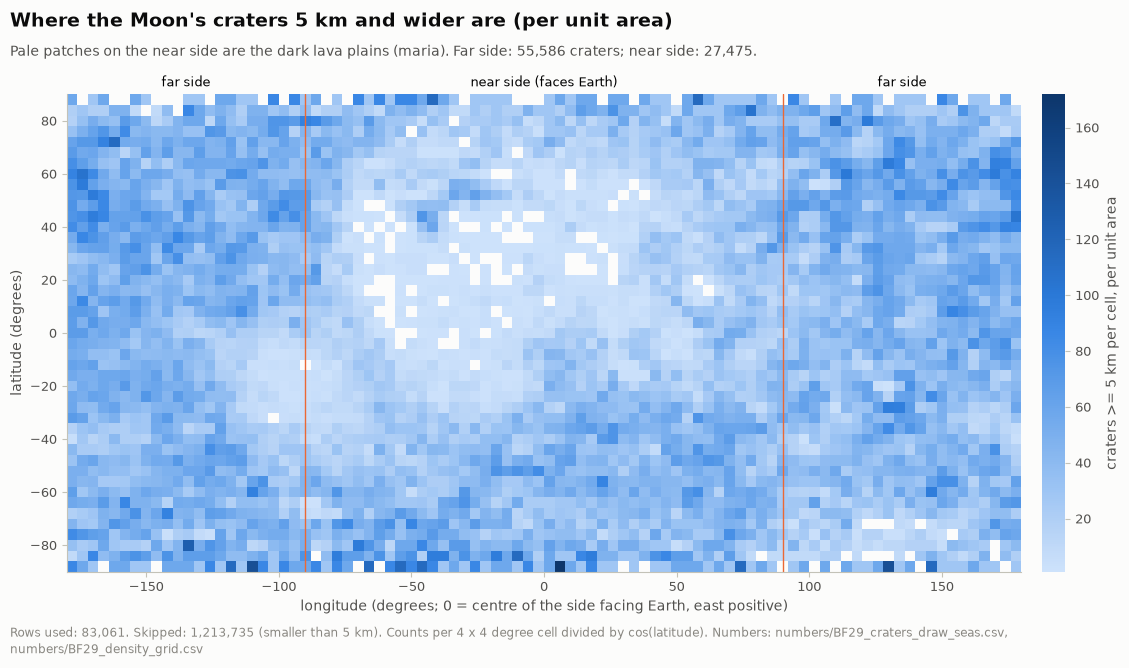

In [2]:
F = Facts(29, "craters_draw_seas")
F.add("rows", N); F.rule("near_cut", 90, "90", "degrees")
for dmin in (1, 5, 20):
    big = cr["diameter_km"] >= dmin
    F.rule(f"d{dmin}", dmin, str(dmin), "km")
    F.add(f"near_{dmin}", int((big & near).sum())); F.add(f"far_{dmin}", int((big & ~near).sum()))
    F.add(f"ratio_{dmin}", (big & ~near).sum() / (big & near).sum(), d((big & ~near).sum() / (big & near).sum(), 1))
ex = cr.iloc[(cr["lon_east"] - 300).abs().argmin()]
F.add("ex_lon_east", ex["lon_east"], d(ex["lon_east"], 1), "degrees"); F.add("ex_lon", ex["lon_east"] - 360, d(ex["lon_east"] - 360, 1), "degrees")
F.rule("cell", 4, "4", "degrees")
F.add("all_5", int((cr["diameter_km"] >= 5).sum())); F.add("ex_lat", ex["lat"], d(ex["lat"], 1), "degrees"); F.add("ex_d", ex["diameter_km"], d(ex["diameter_km"], 2), "km")
F.rule("lon_min", 0, "0"); F.rule("lon_max", 360, "360"); F.rule("lon_half", 180, "180")
print(F.table().to_string()); f29 = F.save()
b5 = cr[cr["diameter_km"] >= 5]
le, be = np.arange(-180, 181, 4), np.arange(-88, 89, 4)
Hc, _, _ = np.histogram2d(b5["lon"], b5["lat"], bins=[le, np.arange(-90, 91, 4)])
lat_mid = (np.arange(-90, 91, 4)[:-1] + np.arange(-90, 91, 4)[1:]) / 2
dens = Hc / np.cos(np.radians(lat_mid))[None, :]
pd.DataFrame(dens, index=le[:-1], columns=np.arange(-90, 90, 4)).round(2).rename_axis("lon_from").to_csv(hp.NUMBERS / "BF29_density_grid.csv")
fig, ax = plt.subplots(figsize=(13, 6.2))
cm = hp.seq_cmap(start_at_surface=False); cm.set_bad(hp.SURFACE)
im = ax.pcolormesh(le, np.arange(-90, 91, 4), np.ma.masked_equal(dens.T, 0), cmap=cm, rasterized=True)
ax.axvline(-90, color=hp.SERIES[1], lw=1); ax.axvline(90, color=hp.SERIES[1], lw=1)
ax.text(0, 93, "near side (faces Earth)", ha="center", fontsize=9.5); ax.text(-135, 93, "far side", ha="center", fontsize=9.5); ax.text(135, 93, "far side", ha="center", fontsize=9.5)
ax.set_xlim(-180, 180); ax.set_ylim(-90, 90); ax.set_aspect("equal"); ax.grid(False)
ax.set_xlabel("longitude (degrees; 0 = centre of the side facing Earth, east positive)"); ax.set_ylabel("latitude (degrees)")
cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02); cb.set_label("craters >= 5 km per cell, per unit area"); cb.outline.set_visible(False)
hp.add_titles(fig, "Where the Moon's craters 5 km and wider are (per unit area)",
              f"Pale patches on the near side are the dark lava plains (maria). Far side: {int((cr['diameter_km'].ge(5) & ~near).sum()):,} craters; "
              f"near side: {int((cr['diameter_km'].ge(5) & near).sum()):,}.",
              hp.caption(len(b5), N - len(b5), "smaller than 5 km", "numbers/BF29_craters_draw_seas.csv, numbers/BF29_density_grid.csv",
                         extra="Counts per 4 x 4 degree cell divided by cos(latitude)."))
c29 = hp.save_chart(fig, "BF29_crater_map"); plt.show()
hp.log_entry("G-BF29", "Beginner finding 29 chart: crater density map (>= 5 km)", step=6, chart=c29, numbers=[f29, "numbers/BF29_density_grid.csv"],
             rows_used=len(b5), rows_skipped=f"{N - len(b5):,} (smaller than 5 km)",
             key_numbers=[f">= 5 km: far {int((cr['diameter_km'].ge(5) & ~near).sum()):,}, near {int((cr['diameter_km'].ge(5) & near).sum()):,}"],
             what_it_shows="The far side has about twice as many 5 km+ craters as the near side; the near side has big empty patches.")

## Finding 30: ten times bigger, 50 to 100 times rarer

           key         value      shown unit             source
0           d1  1.000000e+00          1   km       rule we used
1       n_ge_1  1.296796e+06  1,296,796                our data
2           d2  2.000000e+00          2   km       rule we used
3       n_ge_2  4.430160e+05    443,016                our data
4          d10  1.000000e+01         10   km       rule we used
5      n_ge_10  2.441200e+04     24,412                our data
6         d100  1.000000e+02        100   km       rule we used
7     n_ge_100  3.140000e+02        314                our data
8        d1000  1.000000e+03      1,000   km       rule we used
9    n_ge_1000  3.000000e+00          3                our data
10      r_1_10  5.312125e+01         53                our data
11    r_10_100  7.774522e+01         78                our data
12  r_100_1000  1.046667e+02        105                our data
13    median_d  1.606840e+00        1.6   km           our data
14       max_d  2.491870e+03      2,492 

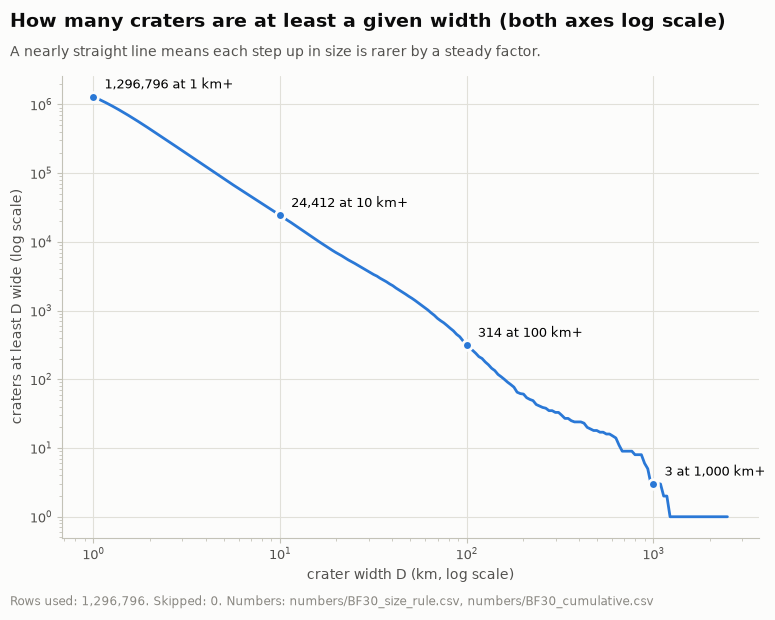

In [3]:
F = Facts(30, "size_rule")
D = cr["diameter_km"]
counts = {k_: int((D >= k_).sum()) for k_ in (1, 2, 10, 100, 1000)}
for k_, v_ in counts.items():
    F.rule(f"d{k_}", k_, n0(k_), "km"); F.add(f"n_ge_{k_}", v_)
F.add("r_1_10", counts[1] / counts[10], n0(counts[1] / counts[10])); F.add("r_10_100", counts[10] / counts[100], n0(counts[10] / counts[100]))
F.add("r_100_1000", counts[100] / counts[1000], n0(counts[100] / counts[1000]))
F.add("median_d", D.median(), d(D.median(), 1), "km"); F.add("max_d", D.max(), n0(D.max()), "km")
F.add("min_d", D.min(), d(D.min(), 2), "km")
F.outside("title_low", 50, "50", source="Field Guide title")
print(F.table().to_string()); f30 = F.save()
grid = np.geomspace(1, D.max(), 200)
Ds = np.sort(D.to_numpy())
cum = len(Ds) - np.searchsorted(Ds, grid, side="left")
pd.DataFrame({"D_km": grid, "craters_at_least_D": cum}).to_csv(hp.NUMBERS / "BF30_cumulative.csv", index=False)
fig, ax = plt.subplots(figsize=(9, 6))
ax.plot(grid, cum, color=hp.SERIES[0])
for k_ in (1, 10, 100, 1000):
    ax.plot(k_, counts[k_], "o", ms=7, color=hp.SERIES[0], mec=hp.SURFACE, mew=2)
    ax.annotate(f"{counts[k_]:,} at {k_:,} km+", (k_, counts[k_]), xytext=(8, 6), textcoords="offset points", fontsize=9)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("crater width D (km, log scale)"); ax.set_ylabel("craters at least D wide (log scale)")
hp.add_titles(fig, "How many craters are at least a given width (both axes log scale)",
              "A nearly straight line means each step up in size is rarer by a steady factor.",
              hp.caption(N, 0, numbers_file="numbers/BF30_size_rule.csv, numbers/BF30_cumulative.csv"))
c30 = hp.save_chart(fig, "BF30_size_rule"); plt.show()
hp.log_entry("G-BF30", "Beginner finding 30 chart: cumulative crater counts", step=6, chart=c30, numbers=[f30, "numbers/BF30_cumulative.csv"],
             rows_used=N, rows_skipped=0, key_numbers=[", ".join(f">= {k_} km: {v_:,}" for k_, v_ in counts.items())],
             what_it_shows="Each tenfold step up in width cuts the count by roughly 50 to 100 times.")

## Finding 31: most craters are nearly round, and the stretched ones lean one way

                  key        value  shown     unit        source
0        median_ratio     1.119631   1.12               our data
1   median_pct_longer    11.963110    12%               our data
2        pct_over_1_5     2.086527   2.1%               our data
3          pct_over_2     0.217536  0.22%               our data
4           ratio_cut     1.500000    1.5           rule we used
5               d_cut     3.000000      3       km  rule we used
6                 bin    15.000000     15  degrees  rule we used
7         n_stretched  4853.000000  4,853               our data
8               bin_0   234.000000    234               our data
9              bin_15   222.000000    222               our data
10             bin_30   311.000000    311               our data
11             bin_45   463.000000    463               our data
12             bin_60   654.000000    654               our data
13             bin_75   691.000000    691               our data
14             bin_90   5

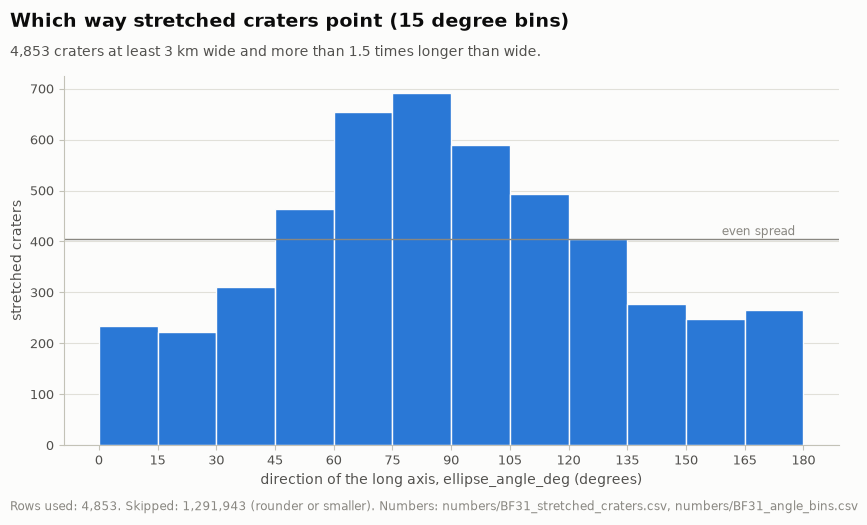

In [4]:
F = Facts(31, "stretched_craters")
ratio = cr["ellipse_major_km"] / cr["ellipse_minor_km"]
F.add("median_ratio", ratio.median(), d(ratio.median(), 2)); F.add("median_pct_longer", 100 * (ratio.median() - 1), p(100 * (ratio.median() - 1)))
F.add("pct_over_1_5", 100 * (ratio > 1.5).mean(), p(100 * (ratio > 1.5).mean(), 1)); F.add("pct_over_2", 100 * (ratio > 2).mean(), p(100 * (ratio > 2).mean(), 2))
F.rule("ratio_cut", 1.5, "1.5"); F.rule("d_cut", 3, "3", "km"); F.rule("bin", 15, "15", "degrees")
stretched = cr[(ratio > 1.5) & (cr["diameter_km"] >= 3)]
ang = stretched["ellipse_angle_deg"] % 180
bins = np.histogram(ang, bins=np.arange(0, 181, 15))[0]
F.add("n_stretched", len(stretched))
for k_, v_ in enumerate(bins):
    F.add(f"bin_{k_ * 15}", int(v_))
F.add("n_60_105", int(((ang >= 60) & (ang < 105)).sum())); F.add("n_0_30", int((ang < 30).sum()))
F.add("share_60_105", 100 * ((ang >= 60) & (ang < 105)).mean(), p(100 * ((ang >= 60) & (ang < 105)).mean()))
F.add("even_share", 100 * 45 / 180, p(100 * 45 / 180))
ex = cr.iloc[(ratio - 1.5).abs().argmin()]
F.add("ex_major", ex["ellipse_major_km"], d(ex["ellipse_major_km"], 2), "km"); F.add("ex_minor", ex["ellipse_minor_km"], d(ex["ellipse_minor_km"], 2), "km")
F.add("ex_ratio", ex["ellipse_major_km"] / ex["ellipse_minor_km"], d(ex["ellipse_major_km"] / ex["ellipse_minor_km"], 2))
F.add("ex_angle", ex["ellipse_angle_deg"], d(ex["ellipse_angle_deg"], 1), "degrees")
F.rule("ratio_2", 2, "2"); F.rule("a60", 60, "60"); F.rule("a105", 105, "105"); F.rule("a0", 0, "0"); F.rule("a30", 30, "30")
print(F.table().to_string()); f31 = F.save()
pd.DataFrame({"angle_from": np.arange(0, 180, 15), "angle_to": np.arange(15, 181, 15), "craters": bins}).to_csv(hp.NUMBERS / "BF31_angle_bins.csv", index=False)
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.bar(np.arange(0, 180, 15), bins, width=15, align="edge", color=hp.SERIES[0], edgecolor=hp.SURFACE, linewidth=1)
ax.axhline(len(stretched) / 12, color=hp.INK_MUTED, lw=1); ax.text(178, len(stretched) / 12 + 8, "even spread", ha="right", fontsize=8.5, color=hp.INK_MUTED)
ax.set_xticks(np.arange(0, 181, 15)); ax.set_xlabel("direction of the long axis, ellipse_angle_deg (degrees)"); ax.set_ylabel("stretched craters"); ax.grid(axis="x", visible=False)
hp.add_titles(fig, "Which way stretched craters point (15 degree bins)",
              f"{len(stretched):,} craters at least 3 km wide and more than 1.5 times longer than wide.",
              hp.caption(len(stretched), N - len(stretched), "rounder or smaller", "numbers/BF31_stretched_craters.csv, numbers/BF31_angle_bins.csv"))
c31 = hp.save_chart(fig, "BF31_stretched_angles"); plt.show()
hp.log_entry("G-BF31", "Beginner finding 31 chart: stretched crater directions", step=6, chart=c31, numbers=[f31, "numbers/BF31_angle_bins.csv"],
             rows_used=len(stretched), rows_skipped=f"{N - len(stretched):,}", key_numbers=["bins: " + ", ".join(str(int(v_)) for v_ in bins)],
             what_it_shows="Stretched craters point between 60 and 105 degrees far more often than between 0 and 30.")

## Finding 32: more craters per square kilometre toward the poles

            key         value    shown     unit                                      source
0   ratio_north      2.974179      3.0                                             our data
1   ratio_south      1.757353      1.8                                             our data
2    n_north_80  24381.000000   24,381                                             our data
3    n_south_80  14406.000000   14,406                                             our data
4    cnt_80_90N  24381.000000   24,381                                             our data
5     cnt_0_10N  89510.000000   89,510                                             our data
6    area_80_90      0.015192    0.015                                             our data
7     area_0_10      0.173648    0.174                                             our data
8    area_ratio     11.430052     11.4                                             our data
9    sp_largest     38.360000       38       km                                 

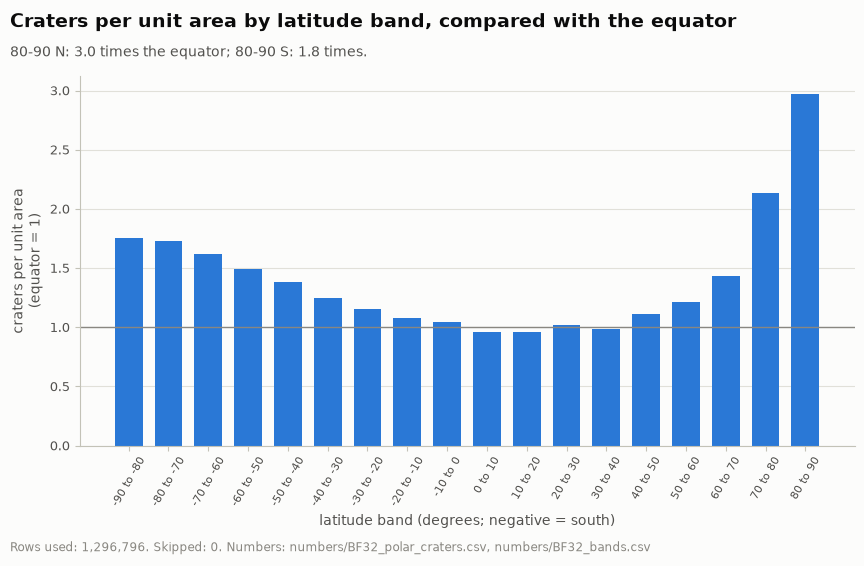

In [5]:
F = Facts(32, "polar_craters")
edges = np.arange(-90, 91, 10)
cnt = np.histogram(cr["lat"], bins=edges)[0]
area = np.sin(np.radians(edges[1:])) - np.sin(np.radians(edges[:-1]))
dens = cnt / area
eq = (dens[8] + dens[9]) / 2  # bands -10..0 and 0..10
F.add("ratio_north", dens[-1] / eq, d(dens[-1] / eq, 1)); F.add("ratio_south", dens[0] / eq, d(dens[0] / eq, 1))
F.add("n_north_80", int((cr["lat"] > 80).sum())); F.add("n_south_80", int((cr["lat"] < -80).sum()))
F.add("cnt_80_90N", int(cnt[-1])); F.add("cnt_0_10N", int(cnt[9]))
F.add("area_80_90", area[-1], d(area[-1], 3)); F.add("area_0_10", area[9], d(area[9], 3))
F.add("area_ratio", area[9] / area[-1], d(area[9] / area[-1], 1))
sp = cr[cr["lat"] < -88.5]
F.add("sp_largest", sp["diameter_km"].max(), n0(sp["diameter_km"].max()), "km"); F.rule("sp_within", 1.5, "1.5", "degrees")
sh = cr.iloc[np.hypot(cr["lat"] + 89.67, (cr["lon"] - 129.78) * np.cos(np.radians(89.67))).argmin()]
F.outside("shack_lat", -89.67, "89.67 S", source="known science (Shackleton crater position)")
F.add("shack_d", sh["diameter_km"], n0(sh["diameter_km"]), "km")
F.rule("band_w", 10, "10", "degrees"); F.rule("lat_80", 80, "80"); F.rule("lat_90", 90, "90"); F.rule("lat_0", 0, "0")
print(F.table().to_string()); f32 = F.save()
pd.DataFrame({"lat_from": edges[:-1], "lat_to": edges[1:], "craters": cnt, "area_share": area / 2, "density_vs_equator": dens / eq}).to_csv(hp.NUMBERS / "BF32_bands.csv", index=False)
fig, ax = plt.subplots(figsize=(10, 4.8))
labs = [f"{lo} to {hi}" for lo, hi in zip(edges[:-1], edges[1:])]
ax.bar(np.arange(18), dens / eq, color=hp.SERIES[0], width=0.7)
ax.axhline(1, color=hp.INK_MUTED, lw=1)
ax.set_xticks(np.arange(18), labs, rotation=60, fontsize=8); ax.set_xlabel("latitude band (degrees; negative = south)")
ax.set_ylabel("craters per unit area\n(equator = 1)"); ax.grid(axis="x", visible=False)
hp.add_titles(fig, "Craters per unit area by latitude band, compared with the equator",
              f"80-90 N: {dens[-1] / eq:.1f} times the equator; 80-90 S: {dens[0] / eq:.1f} times.",
              hp.caption(N, 0, numbers_file="numbers/BF32_polar_craters.csv, numbers/BF32_bands.csv"))
c32 = hp.save_chart(fig, "BF32_polar_bands"); plt.show()
hp.log_entry("G-BF32", "Beginner finding 32 chart: crater density by latitude band", step=6, chart=c32, numbers=[f32, "numbers/BF32_bands.csv"],
             rows_used=N, rows_skipped=0, key_numbers=[f"80-90 N {dens[-1] / eq:.1f}x, 80-90 S {dens[0] / eq:.1f}x the equator"],
             what_it_shows="Crater density rises toward both poles, more in the north.")
hp.edge_case("G", "Full Section G notebook not built (background builders stopped); beginner findings 29-32 were computed in notebooks/BF_G_moon_craters.ipynb.")

## Plain version: "Meet the data" numbers and one plain chart per finding

Numbers for part G's "Meet the data" text: `numbers/BM_G_meet_craters.csv`. New plain charts `charts/K29_...png` to
`charts/K32_...png` (plotted numbers in `numbers/K29_...csv` ...), drawn with `simple_charts`.

In [6]:
kc.plain_style()
allc = hp.read_csv("craters")
M = Meet("G", "meet_craters")
M.add("rows_total", N); M.add("n_columns", len(hp.columns("craters")))
M.add("count_days", N / 86400, d(N / 86400, 1), "days", source="our data (rows ÷ seconds in a day)")
M.add("visit_years", N / 365.25, n0(N / 365.25), "years", source="our data (rows ÷ days in a year)")
M.add("blank_cells", int(allc.isna().sum().sum()))
M.outside("dup_craters", 3, "3", source="README (craters listed twice under different IDs)")
M.rule("min_km", 1, "1", "km")
cop_lat, cop_lon = 9.62, 339.92
dd = np.hypot(allc["lat"] - cop_lat, (allc["lon_east"] - cop_lon) * np.cos(np.radians(cop_lat)))
cand = allc[(dd < 1) & (allc["diameter_km"] > 50)]
cop = cand.loc[dd[cand.index].idxmin()]
M.outside("cop_known_lat", cop_lat, "9.62", "degrees", source="known science (Copernicus crater position)")
M.add("cop_id", 0, str(cop["crater_id"]), source="our data (crater ID)")
for col_, key_, k_ in [("lat", "lat", 2), ("lon_east", "lon_east", 2), ("diameter_km", "d", 1), ("ellipse_major_km", "major", 1),
                       ("ellipse_minor_km", "minor", 1), ("ellipse_eccentricity", "ecc", 2), ("ellipse_angle_deg", "angle", 1),
                       ("rim_arc_fraction", "rim", 2), ("rim_points", "rim_points", 0)]:
    M.add(f"cop_{key_}", cop[col_], d(cop[col_], k_) if k_ else n0(cop[col_]))
M.add("cop_lon", cop["lon_east"] - 360, d(cop["lon_east"] - 360, 2), "degrees")
M.add("cop_stretch", cop["ellipse_major_km"] / cop["ellipse_minor_km"], d(cop["ellipse_major_km"] / cop["ellipse_minor_km"], 2))
M.rule("full_turn", 360, "360", "degrees"); M.rule("half_turn", 180, "180", "degrees")
M.outside("moon_width", 3474.8, "3,475", "km", source="known science (the Moon's diameter)")
M.add("max_d", cr["diameter_km"].max(), n0(cr["diameter_km"].max()), "km")
M.add("max_share", 100 * cr["diameter_km"].max() / 3474.8, p(100 * cr["diameter_km"].max() / 3474.8), source="our data ÷ known science")
M.add("median_d", cr["diameter_km"].median(), d(cr["diameter_km"].median(), 1), "km")
print(M.table().to_string()); fmG = M.save()

               key         value        shown     unit                                             source
0       rows_total  1.296796e+06    1,296,796                                                    our data
1        n_columns  1.000000e+01           10                                                    our data
2       count_days  1.500921e+01         15.0     days                 our data (rows ÷ seconds in a day)
3      visit_years  3.550434e+03        3,550    years                   our data (rows ÷ days in a year)
4      blank_cells  1.520000e+02          152                                                    our data
5      dup_craters  3.000000e+00            3           README (craters listed twice under different IDs)
6           min_km  1.000000e+00            1       km                                       rule we used
7    cop_known_lat  9.620000e+00         9.62  degrees         known science (Copernicus crater position)
8           cop_id  0.000000e+00  04-1-000623 

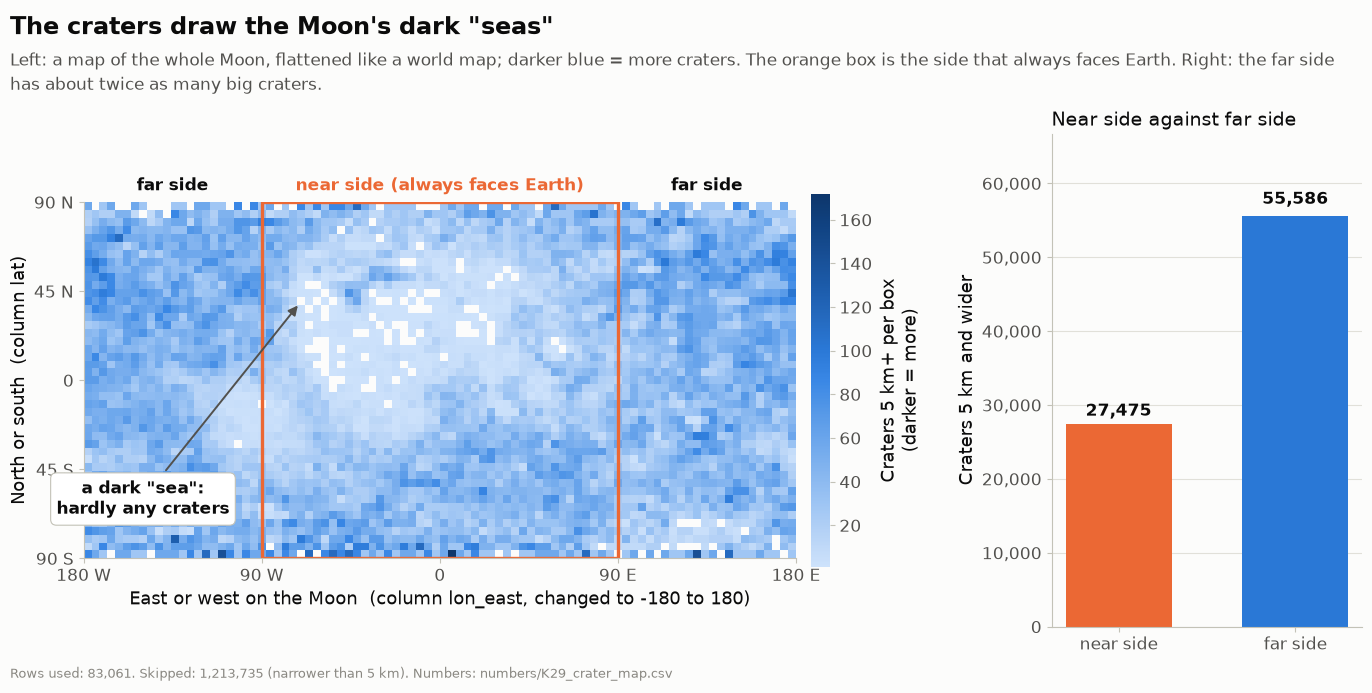

In [7]:
# K29: where the craters 5 km and wider are (left) and near side against far side (right)
lat_e = np.arange(-90, 91, 4)
dens29 = Hc / np.cos(np.radians(lat_mid))[None, :]   # the crater map grid from finding 29 (fair for each box's area)
fig, (axM, axB) = plt.subplots(1, 2, figsize=(16.5, 6.4), gridspec_kw={"width_ratios": [2.4, 1], "wspace": 0.42})
im = axM.pcolormesh(le, lat_e, np.ma.masked_equal(dens29.T, 0), cmap=cm, rasterized=True)
axM.add_patch(plt.Rectangle((-90, -90), 180, 180, fill=False, color=kc.HIGHLIGHT, lw=2.4))
kc.label(axM, 0, 94, "near side (always faces Earth)", ha="center", va="bottom", bold=True, color=hp.SERIES[1])
kc.label(axM, -135, 94, "far side", ha="center", va="bottom", bold=True); kc.label(axM, 135, 94, "far side", ha="center", va="bottom", bold=True)
nearmask = (np.abs(le[:-1] + 2) <= 88)[:, None] & (np.abs(lat_mid) <= 40)[None, :]
low_i, low_j = np.unravel_index(np.argmin(np.where(nearmask, dens29, np.inf)), dens29.shape)
kc.point_at(axM, (le[low_i] + 2, lat_mid[low_j]), "a dark \"sea\":\nhardly any craters", (-150, -60))
axM.set_xlim(-180, 180); axM.set_ylim(-90, 90); axM.set_aspect("equal"); axM.grid(False)
axM.set_xticks([-180, -90, 0, 90, 180], ["180 W", "90 W", "0", "90 E", "180 E"]); axM.set_yticks([-90, -45, 0, 45, 90], ["90 S", "45 S", "0", "45 N", "90 N"])
axM.set_xlabel("East or west on the Moon  (column lon_east, changed to -180 to 180)")
axM.set_ylabel("North or south  (column lat)")
cb = fig.colorbar(im, ax=axM, fraction=0.025, pad=0.02); cb.outline.set_visible(False)
cb.set_label("Craters 5 km+ per box\n(darker = more)")
v29 = [int(((cr["diameter_km"] >= 5) & near).sum()), int(((cr["diameter_km"] >= 5) & ~near).sum())]
axB.bar([0, 1], v29, color=[kc.HIGHLIGHT, kc.MAIN], width=0.6)
for k_, v_ in enumerate(v29):
    kc.label(axB, k_, v_ * 1.02, n0(v_), ha="center", va="bottom", bold=True)
axB.set_xticks([0, 1], ["near side", "far side"]); axB.set_ylim(0, max(v29) * 1.2); kc.plain_axis(axB, "y"); axB.grid(axis="x", visible=False)
axB.set_ylabel("Craters 5 km and wider"); axB.set_title("Near side against far side", fontsize=13.5, color=hp.INK, loc="left")
n29 = hp.save_numbers(pd.DataFrame({"side": ["near", "far"], "craters_5km_plus": v29}), "K29_crater_map")
kc.titles(fig, "The craters draw the Moon's dark \"seas\"",
          "Left: a map of the whole Moon, flattened like a world map; darker blue = more craters. The orange box is the side "
          "that always faces Earth. Right: the far side has about twice as many big craters.",
          hp.caption(int((cr["diameter_km"] >= 5).sum()), N - int((cr["diameter_km"] >= 5).sum()), "narrower than 5 km", n29))
c29_ = kc.save(fig, "K29_crater_map"); plt.show()
hp.log_entry("G-K29", "Simple chart for finding 29: crater map and near/far counts", step=6, chart=c29_, numbers=n29,
             rows_used=int((cr["diameter_km"] >= 5).sum()), key_numbers=[f"near {v29[0]:,}, far {v29[1]:,}"],
             what_it_shows="The near side has big pale patches (the dark seas) with few craters; the far side has about twice as many.")

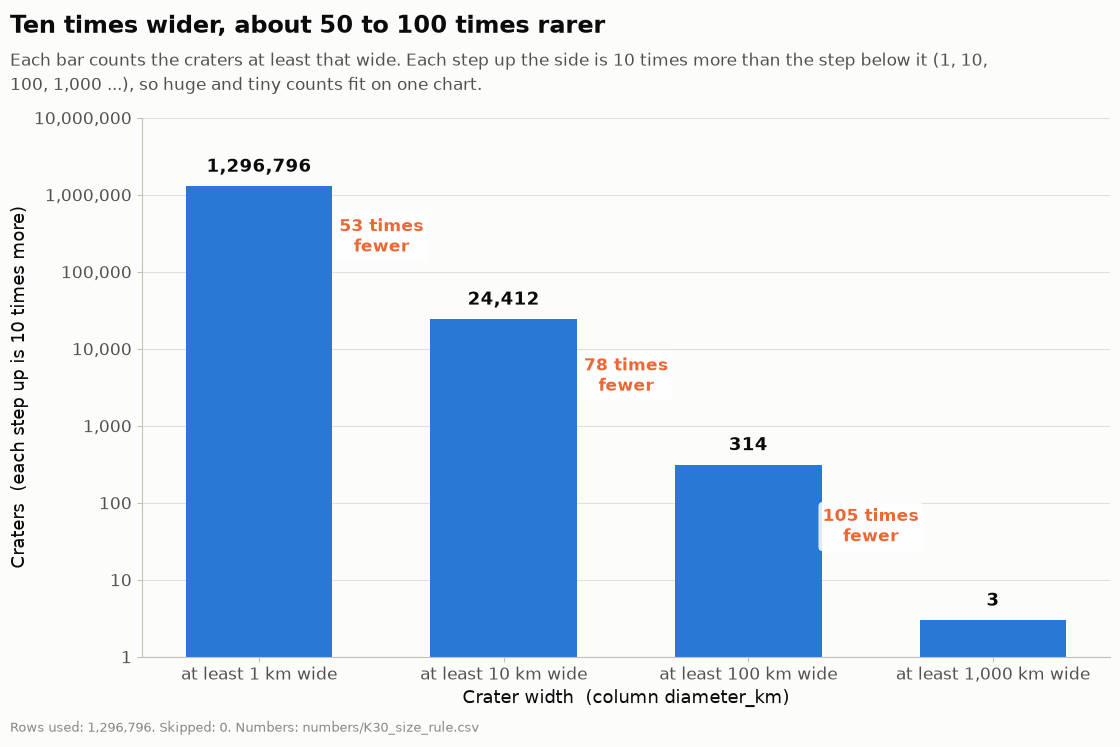

In [8]:
# K30: the staircase: craters at least 1, 10, 100 and 1,000 km wide (each step up the side is 10 times more)
ks = [1, 10, 100, 1000]
vals = [counts[k_] for k_ in ks]
n30 = hp.save_numbers(pd.DataFrame({"at_least_km": ks, "craters": vals}), "K30_size_rule")
fig, ax = plt.subplots(figsize=(12.5, 7))
ax.bar(range(4), vals, color=kc.MAIN, width=0.6)
kc.tens_axis(ax, "y", lo=1, hi=10_000_000)
for k_, v_ in enumerate(vals):
    kc.label(ax, k_, v_ * 1.35, n0(v_), ha="center", va="bottom", bold=True, fontsize=13)
for k_ in range(3):
    kc.label(ax, k_ + 0.5, np.sqrt(vals[k_] * vals[k_ + 1]) * 1.6, f"{n0(vals[k_] / vals[k_ + 1])} times\nfewer", ha="center", va="center",
             color=hp.SERIES[1], bold=True, box=True)
ax.set_xticks(range(4), [f"at least {n0(k_)} km wide" for k_ in ks]); ax.grid(axis="x", visible=False)
ax.set_ylabel("Craters  (each step up is 10 times more)")
ax.set_xlabel("Crater width  (column diameter_km)")
kc.titles(fig, "Ten times wider, about 50 to 100 times rarer",
          "Each bar counts the craters at least that wide. Each step up the side is 10 times more than the step below it "
          "(1, 10, 100, 1,000 ...), so huge and tiny counts fit on one chart.",
          hp.caption(N, 0, "", n30))
c30_ = kc.save(fig, "K30_size_rule"); plt.show()
hp.log_entry("G-K30", "Simple chart for finding 30: the crater staircase", step=6, chart=c30_, numbers=n30, rows_used=N,
             key_numbers=[" / ".join(f"{v_:,}" for v_ in vals)], what_it_shows="Each ten-times step in width cuts the count by about 50 to 100.")

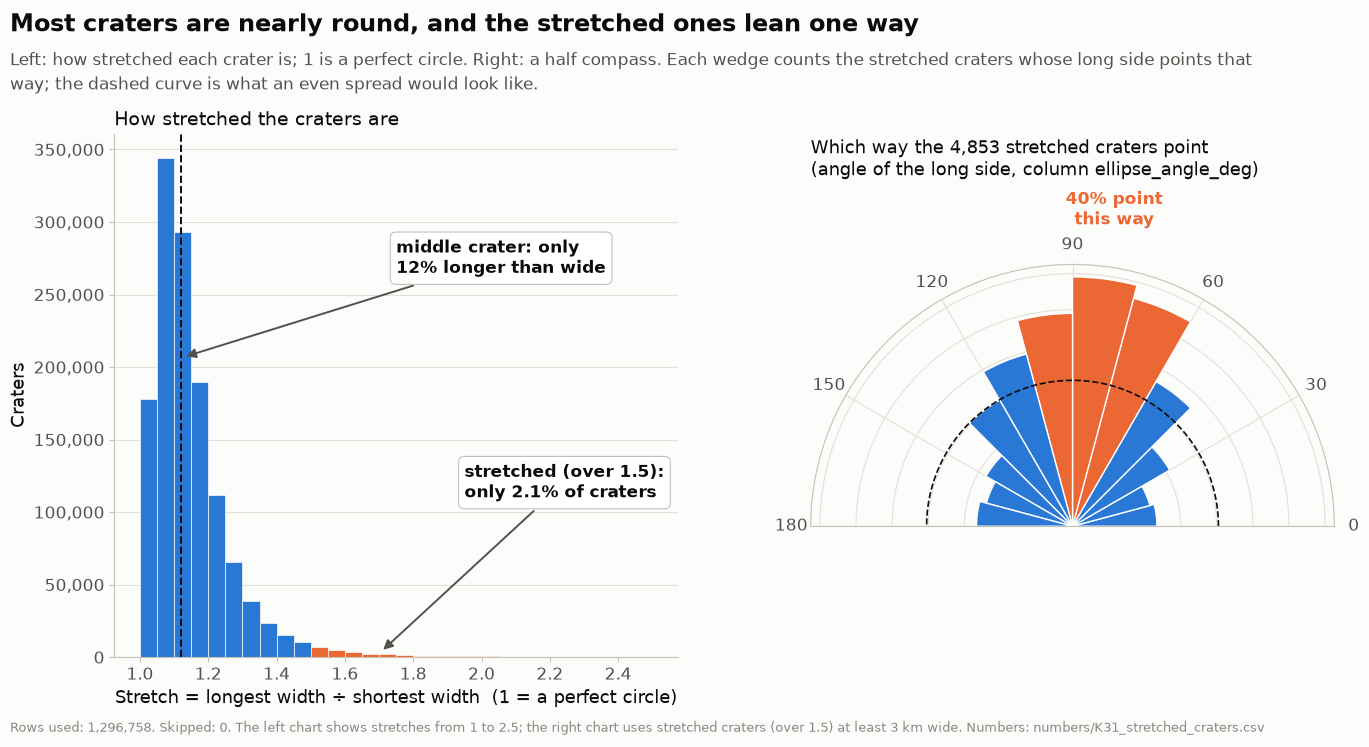

In [9]:
# K31: how stretched the craters are (left) and which way the stretched ones point (right, a half compass)
fig = plt.figure(figsize=(16, 6.8))
axH = fig.add_subplot(1, 2, 1)
rr = ratio[(ratio >= 1) & (ratio <= 2.5)]
hbins = np.arange(1, 2.5001, 0.05)
hc, _ = np.histogram(rr, bins=hbins)
axH.bar(hbins[:-1], hc, width=0.05, align="edge", color=[kc.HIGHLIGHT if x_ >= 1.5 else kc.MAIN for x_ in hbins[:-1]], edgecolor=hp.SURFACE, lw=0.5)
axH.axvline(ratio.median(), color=hp.INK, lw=1.4, ls="--")
kc.point_at(axH, (ratio.median(), hc.max() * 0.6), f"middle crater: only\n{p(100 * (ratio.median() - 1))} longer than wide", (1.75, hc.max() * 0.8), ha="left")
kc.point_at(axH, (1.7, hc[int((1.7 - 1) / 0.05)]), f"stretched (over 1.5):\nonly {p(100 * (ratio > 1.5).mean(), 1)} of craters", (1.95, hc.max() * 0.35), ha="left")
axH.set_xlabel("Stretch = longest width ÷ shortest width  (1 = a perfect circle)"); axH.set_ylabel("Craters"); kc.plain_axis(axH, "y")
axH.grid(axis="x", visible=False); axH.set_title("How stretched the craters are", fontsize=13.5, color=hp.INK, loc="left")
axP = fig.add_subplot(1, 2, 2, projection="polar")
th0 = np.radians(np.arange(0, 180, 15))
axP.bar(th0, bins, width=np.radians(15), align="edge", color=[kc.HIGHLIGHT if 60 <= a_ < 105 else kc.MAIN for a_ in np.arange(0, 180, 15)],
        edgecolor="white", lw=1)
axP.plot(np.linspace(0, np.pi, 100), [len(stretched) / 12] * 100, color=hp.INK, lw=1.2, ls="--")
axP.set_thetamin(0); axP.set_thetamax(180)
axP.set_xticks(np.radians([0, 30, 60, 90, 120, 150, 180]), ["0", "30", "60", "90", "120", "150", "180"])
axP.set_yticklabels([]); axP.grid(color=hp.GRID)
axP.set_title(f"Which way the {n0(len(stretched))} stretched craters point\n(angle of the long side, column ellipse_angle_deg)", fontsize=13,
              color=hp.INK, loc="left", pad=-30)
kc.label(axP, np.radians(82), bins.max() * 1.2, f"{p(100 * ((ang >= 60) & (ang < 105)).mean())} point\nthis way", ha="center", va="bottom",
         color=hp.SERIES[1], bold=True)
n31 = hp.save_numbers(pd.DataFrame({"angle_from": np.arange(0, 180, 15), "angle_to": np.arange(15, 181, 15), "stretched_craters": bins}), "K31_stretched_craters")
kc.titles(fig, "Most craters are nearly round, and the stretched ones lean one way",
          "Left: how stretched each crater is; 1 is a perfect circle. Right: a half compass. Each wedge counts the stretched "
          "craters whose long side points that way; the dashed curve is what an even spread would look like.",
          hp.caption(int(ratio.notna().sum()), 0, "", n31, extra=f"The left chart shows stretches from 1 to 2.5; the right chart uses stretched craters (over 1.5) at least 3 km wide."))
c31_ = kc.save(fig, "K31_stretched_craters"); plt.show()
hp.log_entry("G-K31", "Simple chart for finding 31: stretch and a half-compass of directions", step=6, chart=c31_, numbers=n31,
             rows_used=len(stretched), key_numbers=[f"60 to 105 degrees: {int(((ang >= 60) & (ang < 105)).sum()):,} of {len(stretched):,}"],
             what_it_shows="Most craters are nearly round; stretched ones favour 60 to 105 degrees.")

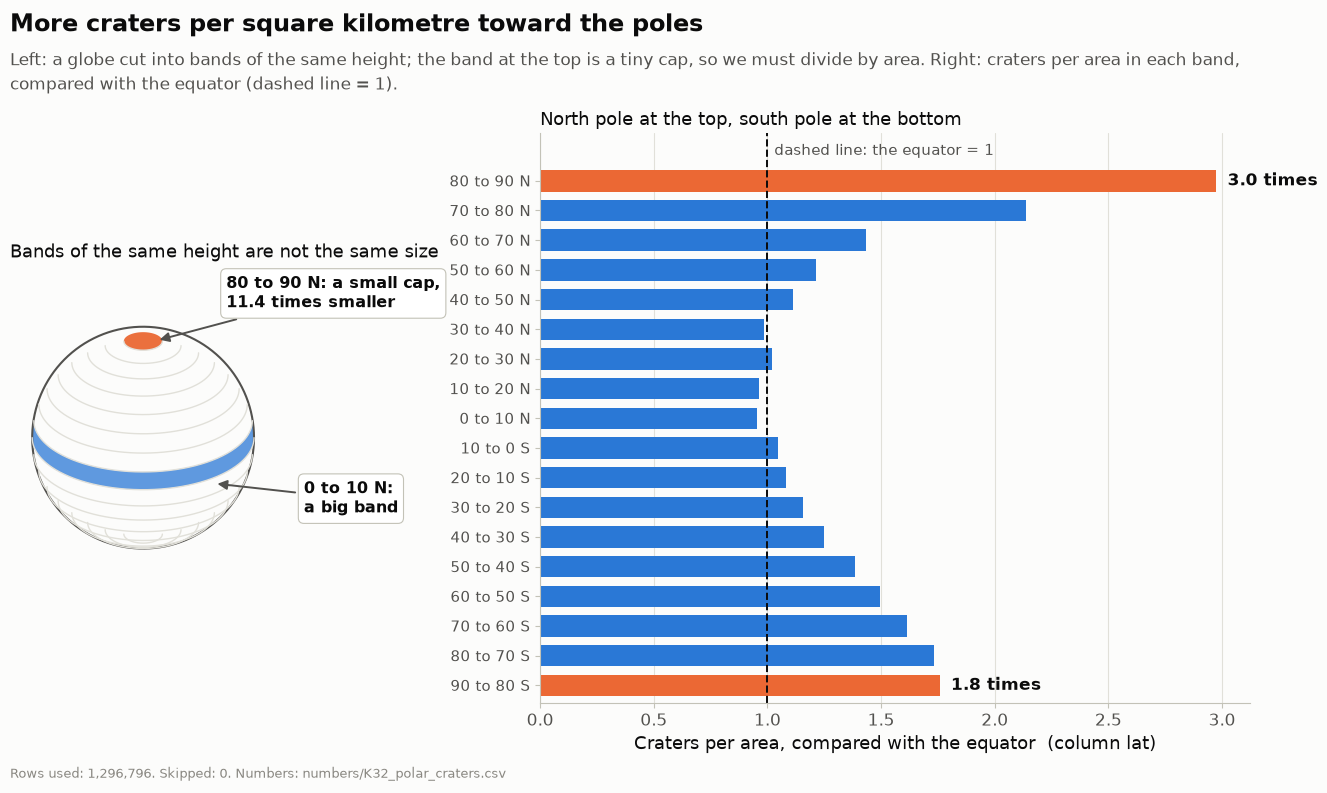

In [10]:
# K32: why we divide by area (left, a globe with two bands) and craters per area by band (right, north at the top)
fig, (axG, axR) = plt.subplots(1, 2, figsize=(16, 7.4), gridspec_kw={"width_ratios": [1, 1.6], "wspace": 0.15})
# a globe seen from a little above (tilt), so latitude lines are ovals and the polar cap shows as a small disc
tilt = np.radians(28)
tt = np.linspace(0, 2 * np.pi, 400)
front = np.linspace(np.pi, 2 * np.pi, 200)                                   # the half of each oval facing us
lat_oval = lambda phi, th: (np.cos(phi) * np.cos(th), np.sin(phi) * np.cos(tilt) + np.cos(phi) * np.sin(th) * np.sin(tilt))  # noqa: E731
axG.plot(np.cos(tt), np.sin(tt), color=hp.INK_2, lw=1.5)
for lat_ in range(-80, 90, 10):
    u_, w_ = lat_oval(np.radians(lat_), front)
    axG.plot(u_, w_, color=hp.GRID, lw=1)
u0, w0 = lat_oval(0.0, front); u1, w1 = lat_oval(np.radians(10), front)
axG.fill(np.r_[u0, u1[::-1]], np.r_[w0, w1[::-1]], color=kc.MAIN, alpha=0.75, lw=0)
uc, wc = lat_oval(np.radians(80), tt)
axG.fill(uc, wc, color=kc.HIGHLIGHT, alpha=0.95, lw=0)
kc.point_at(axG, (0.62, float(lat_oval(np.radians(5), 1.5 * np.pi)[1]) - 0.02), "0 to 10 N:\na big band", (1.45, -0.55), ha="left", fontsize=11.5)
kc.point_at(axG, (0.1, float(np.sin(np.radians(80)) * np.cos(tilt))), f"80 to 90 N: a small cap,\n{d(area[9] / area[-1], 1)} times smaller", (0.75, 1.3),
            ha="left", fontsize=11.5)
axG.set_aspect("equal"); axG.set_xlim(-1.2, 2.8); axG.set_ylim(-1.2, 1.55); axG.axis("off")
axG.set_title("Bands of the same height are not the same size", fontsize=13, color=hp.INK, loc="left")
ratio_band = dens / eq
labs32 = [f"{abs(lo)} to {abs(hi)} {'S' if hi <= 0 else 'N'}" for lo, hi in zip(edges[:-1], edges[1:])]
yy32 = np.arange(18)
axR.barh(yy32, ratio_band, color=[kc.HIGHLIGHT if k_ in (0, 17) else kc.MAIN for k_ in range(18)], height=0.72)
axR.axvline(1, color=hp.INK, lw=1.4, ls="--")
kc.label(axR, 1.03, 17.75, "dashed line: the equator = 1", ha="left", va="bottom", fontsize=11, color=hp.INK_2)
axR.set_ylim(-0.6, 18.6)
for k_ in (0, 17):
    kc.label(axR, ratio_band[k_] + 0.05, k_, f"{d(ratio_band[k_], 1)} times", ha="left", va="center", bold=True)
axR.set_yticks(yy32, labs32, fontsize=10.5); axR.grid(axis="y", visible=False)
axR.set_xlabel("Craters per area, compared with the equator  (column lat)")
axR.set_title("North pole at the top, south pole at the bottom", fontsize=13, color=hp.INK, loc="left")
n32 = hp.save_numbers(pd.DataFrame({"band": labs32, "craters": cnt, "per_area_vs_equator": ratio_band.round(3)}), "K32_polar_craters")
kc.titles(fig, "More craters per square kilometre toward the poles",
          "Left: a globe cut into bands of the same height; the band at the top is a tiny cap, so we must divide by area. "
          "Right: craters per area in each band, compared with the equator (dashed line = 1).",
          hp.caption(N, 0, "", n32))
c32_ = kc.save(fig, "K32_polar_craters"); plt.show()
hp.log_entry("G-K32", "Simple chart for finding 32: why divide by area, and craters per area by band", step=6, chart=c32_, numbers=n32,
             rows_used=N, key_numbers=[f"north polar band {ratio_band[17]:.1f}x, south {ratio_band[0]:.1f}x the equator"],
             what_it_shows="Per area, both polar bands have more craters than the equator, the north most of all.")